# 6. Curvas de treinamento

← [Treino e experimentos](05_training.ipynb) · [índice](README.pt-BR.md) · [Modelo final e análises](07_final_model.ipynb) →

Curvas de loss e acurácia, comparações entre grupos de experimentos e diagnóstico de overfitting.

## Curvas de treinamento

Curvas de loss e de acurácia, no treino e na validação, ao longo das épocas dos principais modelos. A linha
tracejada marca a época escolhida pelo *early stopping*.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from svhn_utils import figures_dir, load_results
FIG_DIR = figures_dir("06_training_curves")   # figuras deste notebook em outputs/figures/06_training_curves/

results = load_results()

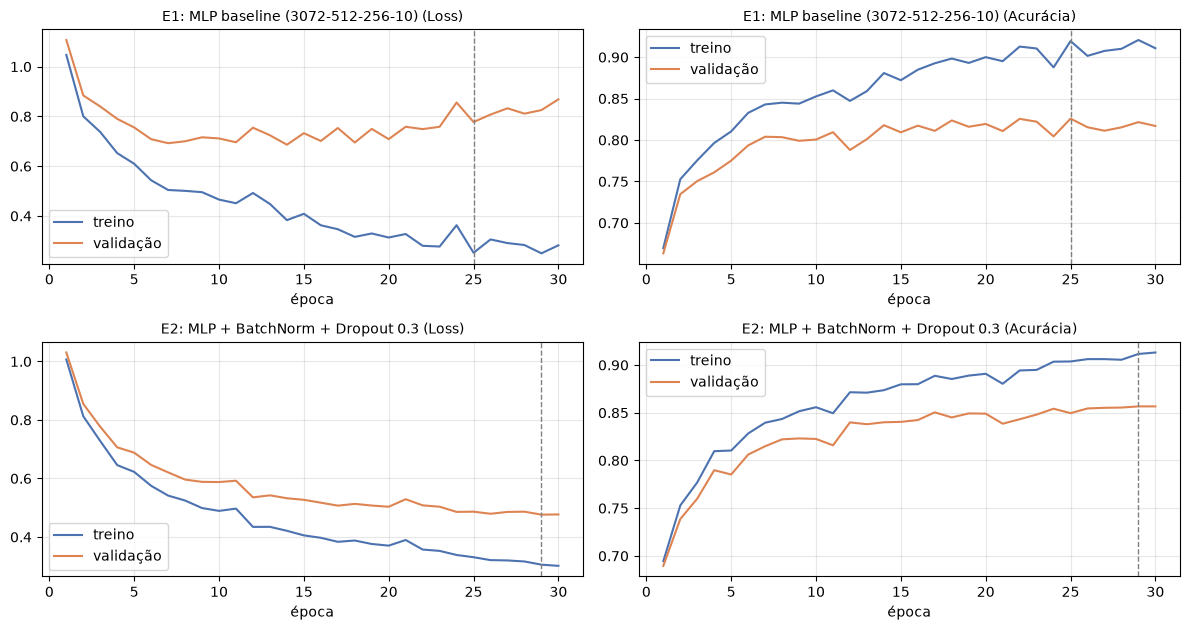

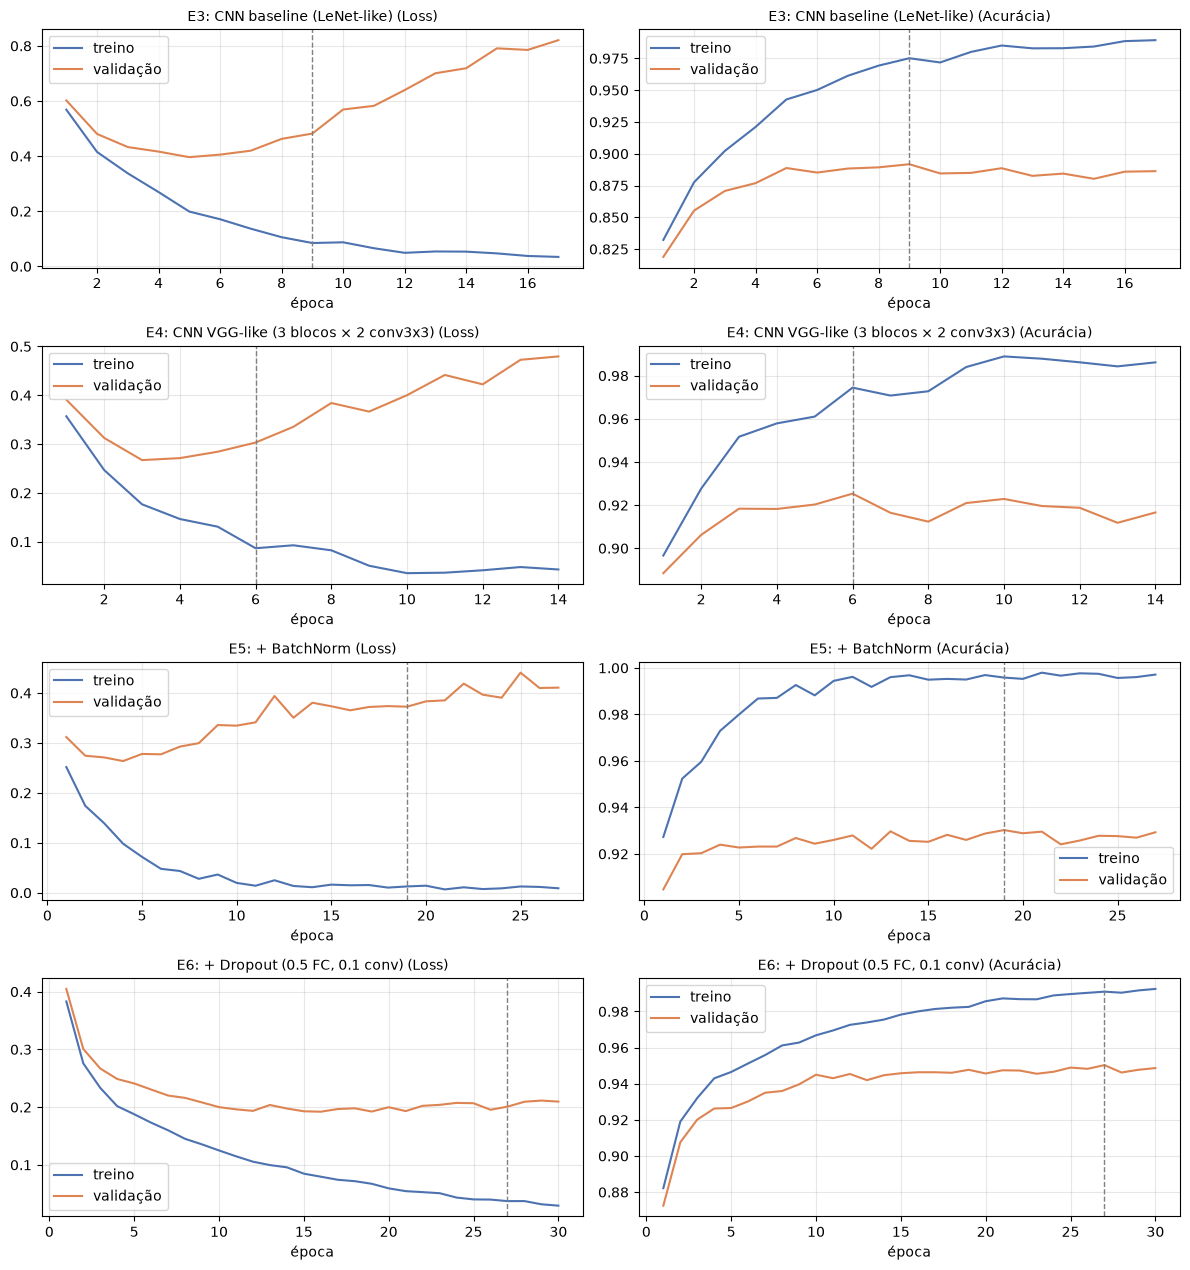

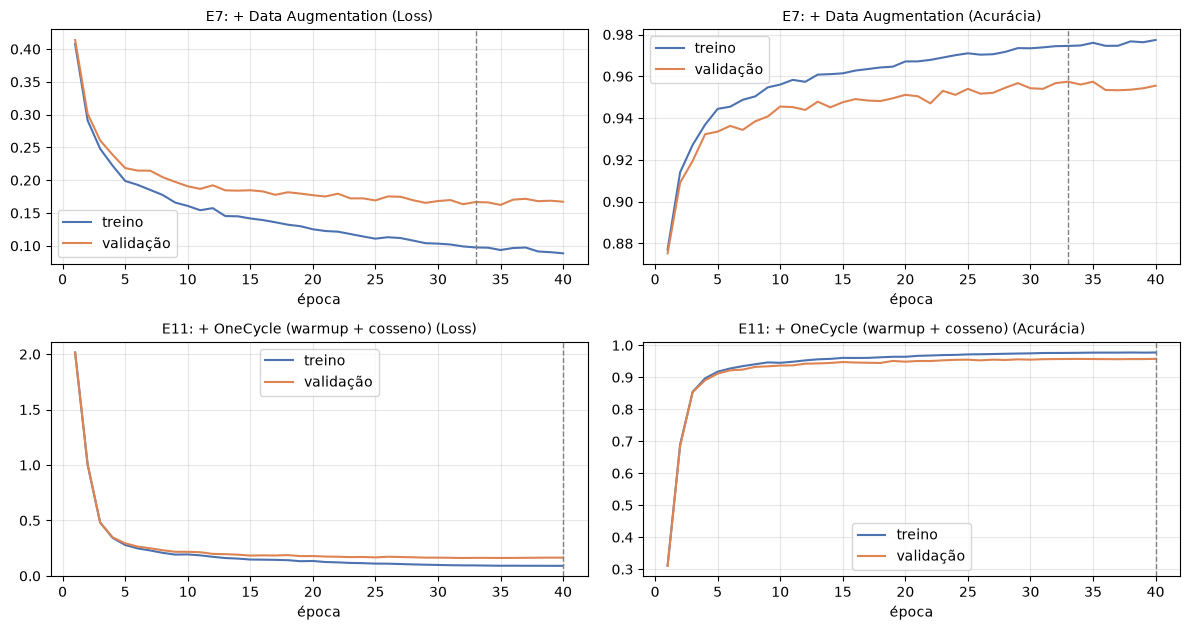

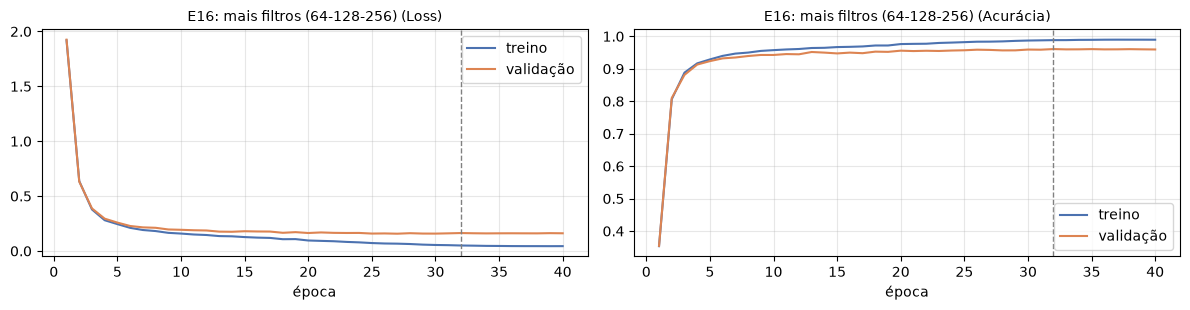

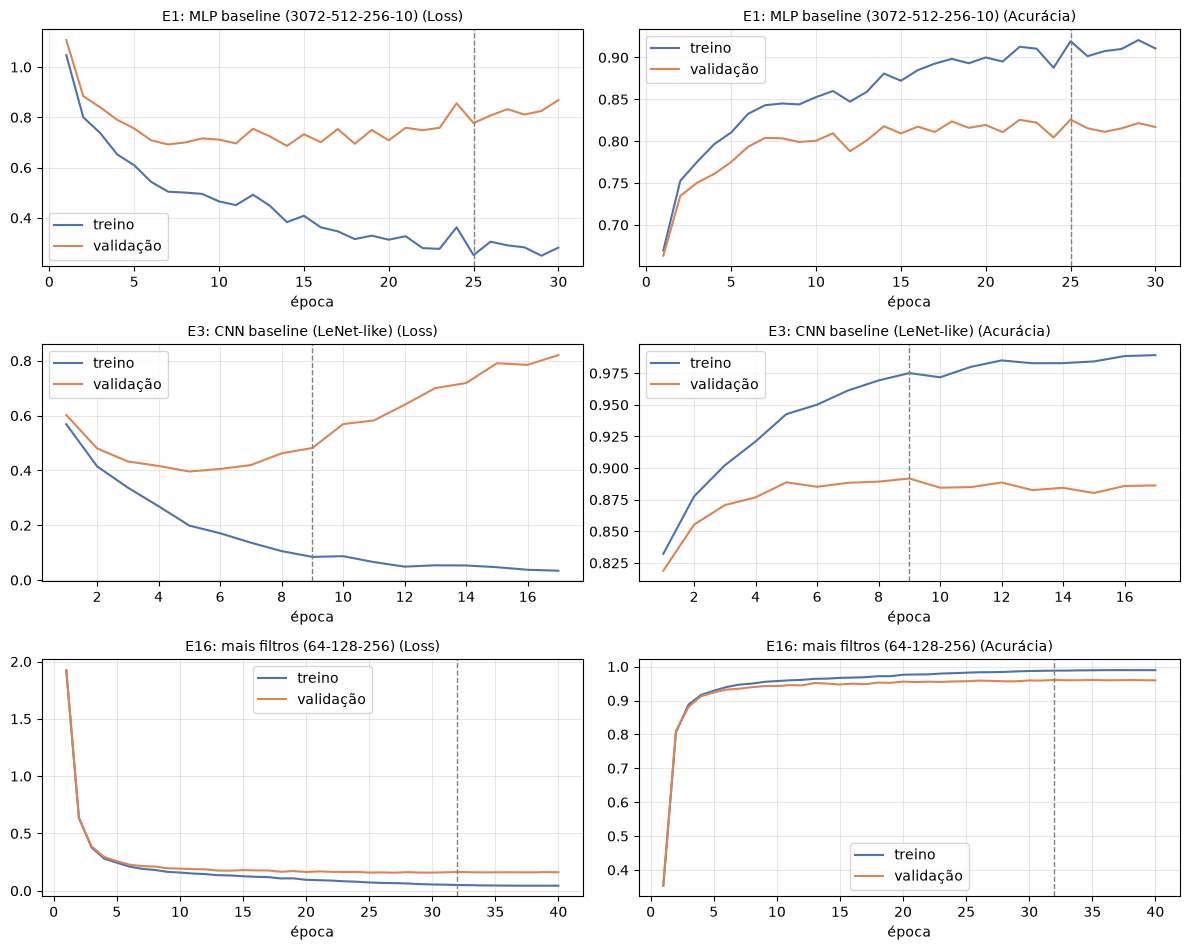

In [2]:
def plot_curves(ids, fname=None):
    fig, axes = plt.subplots(len(ids), 2, figsize=(12, 3.2 * len(ids)), squeeze=False)
    for row, i in zip(axes, ids):
        h, r = results[i]["history"], results[i]
        ep = np.arange(1, len(h["train_loss"]) + 1)
        for ax, key, label in [(row[0], "loss", "Loss"), (row[1], "acc", "Acurácia")]:
            ax.plot(ep, h[f"train_{key}"], label="treino", color="#4C72B0")
            ax.plot(ep, h[f"val_{key}"], label="validação", color="#DD8452")
            ax.axvline(r["best_epoch"], ls="--", color="gray", lw=1)
            ax.set_title(f"{i}: {r['desc']} ({label})", fontsize=10)
            ax.set_xlabel("época"); ax.grid(alpha=.3); ax.legend()
    plt.tight_layout()
    if fname: plt.savefig(FIG_DIR / fname, dpi=150)
    plt.show()

plot_curves(["E1", "E2"], "curves_mlp.png")
plot_curves(["E3", "E4", "E5", "E6"], "curves_cnn.png")
plot_curves(["E7", "E11"], "curves_cnn_aug.png")
plot_curves(["E16"], "curves_best_model.png")
plot_curves(["E1", "E3", "E16"], "curves_main.png")

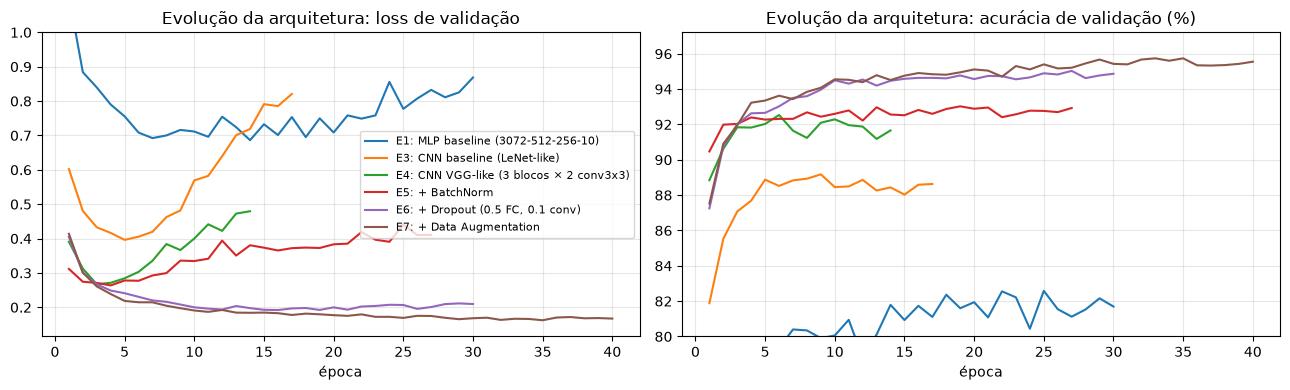

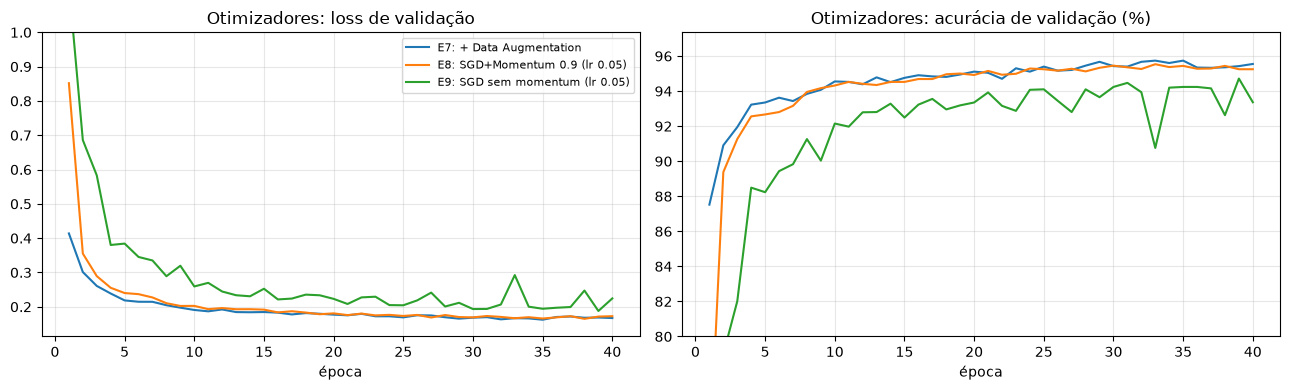

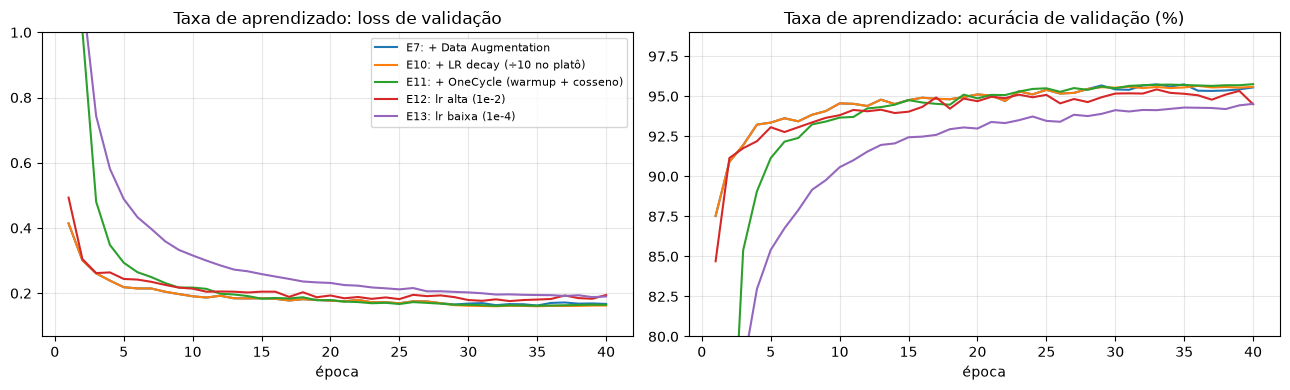

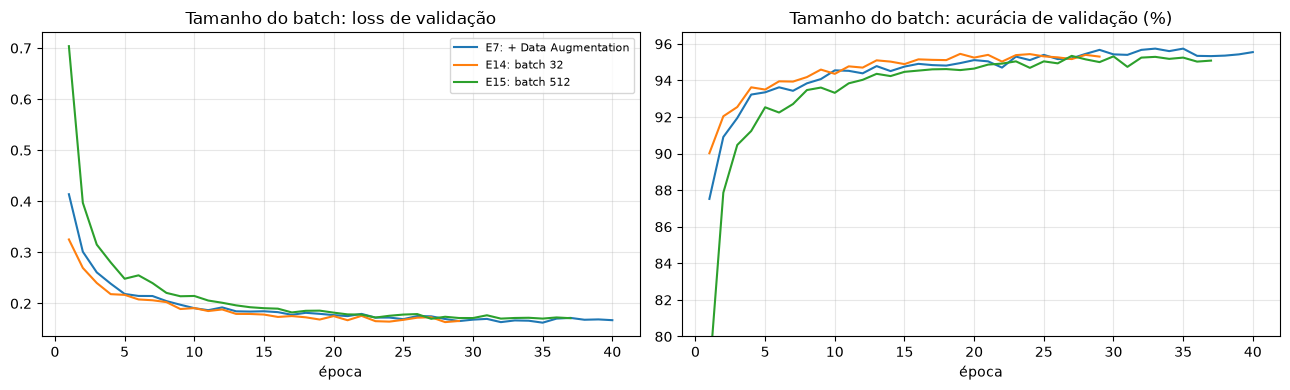

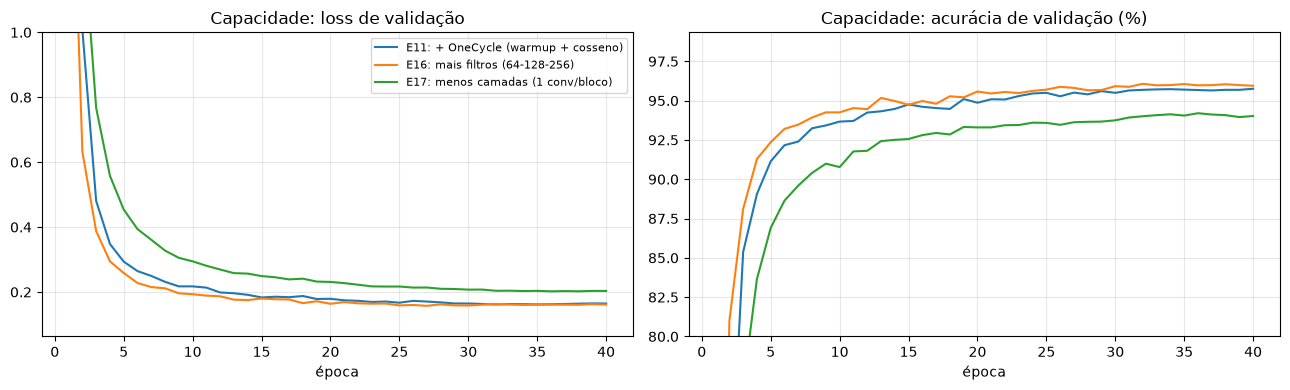

In [3]:
def compare(ids, title, fname=None):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for i in ids:
        h = results[i]["history"]; ep = np.arange(1, len(h["val_acc"]) + 1)
        axes[0].plot(ep, h["val_loss"], label=f"{i}: {results[i]['desc']}")
        axes[1].plot(ep, np.array(h["val_acc"]) * 100, label=i)
    axes[0].set_title(f"{title}: loss de validação"); axes[1].set_title(f"{title}: acurácia de validação (%)")
    axes[0].set_ylim(top=min(1.0, axes[0].get_ylim()[1]))
    axes[1].set_ylim(bottom=max(80, axes[1].get_ylim()[0]))
    for ax in axes: ax.set_xlabel("época"); ax.grid(alpha=.3)
    axes[0].legend(fontsize=8)
    plt.tight_layout()
    if fname: plt.savefig(FIG_DIR / fname, dpi=150)
    plt.show()

compare(["E1", "E3", "E4", "E5", "E6", "E7"], "Evolução da arquitetura", "compare_architecture.png")
compare(["E7", "E8", "E9"], "Otimizadores", "compare_optimizers.png")
compare(["E7", "E10", "E11", "E12", "E13"], "Taxa de aprendizado", "compare_lr.png")
compare(["E7", "E14", "E15"], "Tamanho do batch", "compare_batch.png")
compare(["E11", "E16", "E17"], "Capacidade", "compare_capacity.png")

### Diagnóstico automático

A tabela abaixo resume, para cada experimento:
- **gap**: diferença entre a acurácia de treino e a de validação na melhor época. Um gap grande indica *overfitting*.
- **↑ val loss**: quanto a loss de validação subiu desde o seu mínimo até a última época. Se ela sobe enquanto a de treino cai, há *overfitting*.
- **oscilação**: desvio padrão da variação da acurácia de validação de uma época para a outra, nas últimas 10 épocas. Valores altos indicam *instabilidade*.
- **acc treino**: quando fica baixa, há *underfitting* (falta capacidade ou treino).

In [4]:
diag = []
for i, r in results.items():
    h = r["history"]
    vl = np.array(h["val_loss"]); va = np.array(h["val_acc"])
    osc = np.std(np.diff(va[-10:])) * 100 if len(va) > 2 else 0
    diag.append({"Exp.": i, "Modificação": r["desc"],
                 "acc treino (%)": round(r["train_acc"] * 100, 2), "acc val (%)": round(r["val_acc"] * 100, 2),
                 "gap (p.p.)": round((r["train_acc"] - r["val_acc"]) * 100, 2),
                 "↑ val loss": round(vl[-1] - vl.min(), 4),
                 "oscilação val (p.p.)": round(osc, 2)})
pd.DataFrame(diag)

,Exp.,Modificação,acc treino (%),acc val (%),gap (p.p.),↑ val loss,oscilação val (p.p.)
0,E1,MLP baseline (3072-512-256-10),91.94,82.58,9.36,0.1823,1.16
1,E2,MLP + BatchNorm + Dropout 0.3,91.16,85.67,5.49,0.0007,0.32
2,E3,CNN baseline (LeNet-like),97.51,89.18,8.34,0.4246,0.42
3,E4,CNN VGG-like (3 blocos × 2 conv3x3),97.45,92.53,4.91,0.2123,0.56
4,E5,+ BatchNorm,99.58,93.02,6.56,0.1471,0.23
5,E6,"+ Dropout (0.5 FC, 0.1 conv)",99.10,95.03,4.07,0.0175,0.19
6,E7,+ Data Augmentation,97.45,95.74,1.71,0.0049,0.18
7,E8,SGD+Momentum 0.9 (lr 0.05),97.21,95.54,1.68,0.0078,0.15
8,E9,SGD sem momentum (lr 0.05),95.88,94.72,1.17,0.0366,1.84
9,E10,+ LR decay (÷10 no platô),97.77,95.65,2.13,0.0023,0.07


### Análise das curvas

**Overfitting nos modelos sem regularização (E1, E3, E4, E5).** Nesses modelos, a loss de
validação atinge o mínimo cedo e depois sobe enquanto a de treino continua caindo. A
acurácia de validação estaciona.
- **CNN baseline (E3):** a loss de validação vai de 0,40 (época 5) a 0,82 (época 17). O treino chega a 97,5% e a validação fica em 89%, um gap de 8,3 p.p.
- **E5 (+ BatchNorm):** o treino chega a 99,6% e o gap aumenta (6,6 p.p.). O BatchNorm costuma melhorar o fluxo do gradiente e ter um leve efeito regularizador. O primeiro efeito aparece claramente: o treino converge muito mais rápido. Já o efeito regularizador foi pequeno aqui (+0,5 p.p. na validação) e não impediu a rede de memorizar o treino. Por isso, foi preciso combinar o BatchNorm com Dropout.
- **Early stopping:** nesses modelos, ele é o que impede que a acurácia final piore.

**A regularização resolve o overfitting.**
- **Dropout (E6):** a loss de validação para de subir (o aumento a partir do mínimo cai de 0,15 para 0,02), o gap cai para 4,1 p.p. e a validação sobe para 95%.
- **Data augmentation (E7):** o gap cai para 1,7 p.p. As duas curvas caminham juntas até o fim, e a rede continua aprendendo por mais épocas (melhor época 33 de 40).

**Underfitting.**
- **MLP:** mesmo com 1,7 milhão de parâmetros, a MLP não passa de cerca de 86% de validação. Ao achatar a imagem, ela perde a estrutura espacial: o mesmo dígito deslocado alguns pixels vira um vetor completamente diferente.
- **E13 (lr 1e-4) e E17 (1 conv por bloco):** mostram um underfitting leve. A acurácia de treino fica baixa (cerca de 95%), a validação ainda estava subindo na última época (E13), ou a rede menor não tem capacidade suficiente (E17).

**Instabilidade.**
- **SGD sem momentum (E9):** é o caso mais instável. A acurácia de validação oscila bastante de uma época para outra (desvio de 1,84 p.p., com queda de quase 4 p.p. na época 33). Ela também converge bem mais devagar que o SGD com momentum e o Adam.
- **lr alta (E12, 1e-2):** também oscila mais que o normal (0,33 p.p.).
- **Schedulers (E10, E11):** as curvas mais suaves são as dos modelos com decaimento da taxa de aprendizado (oscilação de no máximo 0,07 p.p.). Reduzir a lr no fim do treino estabiliza a convergência.

**Observação:** em todos os modelos com augmentation, a acurácia no teste ficou cerca de 1 p.p. acima
da de validação. Isso pode refletir diferenças entre os dois conjuntos, mas essa comparação, sozinha, não
mostra que o teste seja mais fácil. O teste não foi usado em nenhuma decisão.

**Tempo por época:** os valores de `s/época` de E3 e E11 estão inflados por fatores externos
(execução dentro do kernel Jupyter e limitação de desempenho por bateria baixa) e não refletem o
custo dos modelos.